<div align="center">

# Лабораторна робота № 6

## Нейронна регресія для табличних даних у TensorFlow

*Дисципліна «Інтелектуальний аналіз даних»*

</div>

<br>

**Мета роботи:** Навчитися готувати реальні табличні дані без витоку інформації, порівнювати нейромережу з класичними моделями, контролювати навчання за validation, аналізувати помилки та зберігати весь процес прогнозування.

<br>

<div align="center">

Студентка: Сабадаш Анастасія  
Група: МІТ-31  
Варіант: 2  

</div>

In [15]:
from pathlib import Path
import io, json, base64, gzip, importlib.util
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, joblib
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

TF_AVAILABLE = importlib.util.find_spec('tensorflow') is not None
if TF_AVAILABLE:
    import tensorflow as tf
    from tensorflow import keras
    from tensorflow.keras import layers
SEED = 42
ARTIFACTS = Path('Lab6/artifacts')
ARTIFACTS.mkdir(parents=True, exist_ok=True)
print('TensorFlow:', tf.__version__ if TF_AVAILABLE else 'відсутній — блоки NN буде пропущено')
print('scikit-learn:', sklearn.__version__)

TensorFlow: 2.21.0
scikit-learn: 1.9.1


## Читання та перевірка даних

In [16]:
# Вбудована копія даних для роботи без мережі.
DATA_GZIP_BASE64 = 'H4sICJtK12oC/3WNQQqEMAwAvfOWvKAHu/cuzUshK1L/UHDv3vQhB3kZZCZpkoxk82bC3m1N2Z941+Zl318l1e2zG5v+V3v/d7f+c9a+vV3+Xv/u9bfa++f9r+8b'
local_file = Path('auto-mpg.data')
raw_text = (local_file.read_text() if local_file.exists() else
            gzip.decompress(base64.b64decode(DATA_GZIP_BASE64)).decode())
columns = ['mpg', 'cylinders', 'displacement', 'horsepower', 'weight',
           'acceleration', 'model_year', 'origin', 'car_name']
data = pd.read_csv(io.StringIO(raw_text), sep=r'\s+', names=columns,
                   na_values='?', quotechar='"')
display(data.head())
display(pd.DataFrame({'Тип': data.dtypes.astype(str), 'Пропуски': data.isna().sum()}))
print('Рядків:', len(data), '| Повних дублікатів:', data.duplicated().sum())
display(data.loc[data.horsepower.isna()].head())
data = data.dropna(subset=['mpg']).copy()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
0,18.0,8,307.0,130.0,3504.0,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693.0,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436.0,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433.0,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449.0,10.5,70,1,ford torino


,Тип,Пропуски
mpg,float64,0
cylinders,int64,0
displacement,float64,0
horsepower,float64,6
weight,float64,0
acceleration,float64,0
model_year,int64,0
origin,int64,0
car_name,str,0


Рядків: 398 | Повних дублікатів: 0


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
32,25.0,4,98.0,NaN,2046.0,19.0,71,1,ford pinto
126,21.0,6,200.0,NaN,2875.0,17.0,74,1,ford maverick
330,40.9,4,85.0,NaN,1835.0,17.3,80,2,renault lecar deluxe
336,23.6,4,140.0,NaN,2905.0,14.3,80,1,ford mustang cobra
354,34.5,4,100.0,NaN,2320.0,15.8,81,2,renault 18i


## Три вибірки й один препроцесор

In [17]:
X = data.drop(columns=['mpg', 'car_name'])
y = data.mpg.astype('float32')

X_train, X_holdout, y_train, y_holdout = train_test_split(
    X, y, test_size=0.30, random_state=SEED
)
X_val, X_test, y_val, y_test = train_test_split(
    X_holdout, y_holdout, test_size=0.50, random_state=SEED
)

numeric_features = [c for c in X if c != 'origin']
preprocessor = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), numeric_features),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ]), ['origin']),
])

X_train_p = preprocessor.fit_transform(X_train).astype('float32')
X_val_p = preprocessor.transform(X_val).astype('float32')
X_test_p = preprocessor.transform(X_test).astype('float32')

feature_names = preprocessor.get_feature_names_out()

for name, matrix, target in [('train', X_train_p, y_train),
                            ('validation', X_val_p, y_val),
                            ('test', X_test_p, y_test)]:
    print(name, matrix.shape, matrix.dtype)
    assert matrix.ndim == 2 and len(matrix) == len(target)
    assert matrix.shape[1] == len(feature_names) and np.isfinite(matrix).all()
    display(pd.DataFrame(matrix[:3], columns=feature_names))

missing_hp = X_train.horsepower.isna().to_numpy()
print('Медіана horsepower у train:', X_train.horsepower.median())
print('Заповнені horsepower:', X_train_p[missing_hp, numeric_features.index('horsepower')])

assert set(X_train.index).isdisjoint(X_val.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_val.index).isdisjoint(X_test.index)

train (278, 9) float32


,num__cylinders,num__displacement,num__horsepower,num__weight,num__acceleration,num__model_year,cat__origin_1,cat__origin_2,cat__origin_3
0,8.0,350.0,145.0,4440.0,14.0,75.0,1.0,0.0,0.0
1,4.0,140.0,72.0,2401.0,19.5,73.0,1.0,0.0,0.0
2,6.0,200.0,85.0,2587.0,16.0,70.0,1.0,0.0,0.0


validation (60, 9) float32


,num__cylinders,num__displacement,num__horsepower,num__weight,num__acceleration,num__model_year,cat__origin_1,cat__origin_2,cat__origin_3
0,4.0,91.0,60.0,1800.0,16.4,78.0,0.0,0.0,1.0
1,4.0,151.0,88.0,2740.0,16.0,77.0,1.0,0.0,0.0
2,4.0,91.0,68.0,1970.0,17.6,82.0,0.0,0.0,1.0


test (60, 9) float32


,num__cylinders,num__displacement,num__horsepower,num__weight,num__acceleration,num__model_year,cat__origin_1,cat__origin_2,cat__origin_3
0,4.0,120.0,97.0,2506.0,14.5,72.0,0.0,0.0,1.0
1,4.0,121.0,115.0,2671.0,13.5,75.0,0.0,1.0,0.0
2,8.0,318.0,150.0,4237.0,14.5,73.0,1.0,0.0,0.0


Медіана horsepower у train: 92.0
Заповнені horsepower: [92. 92. 92. 92. 92.]


## Baseline та форми прогнозів

In [18]:
def regression_metrics(actual, predicted):
    actual = np.asarray(actual).reshape(-1)
    predicted = np.asarray(predicted).reshape(-1)
    assert actual.shape == predicted.shape
    return {'MAE': mean_absolute_error(actual, predicted),
            'RMSE': np.sqrt(mean_squared_error(actual, predicted)),
            'R2': r2_score(actual, predicted)}

def predict_values(model, matrix):
    pred = (model.predict(matrix, verbose=0) if TF_AVAILABLE and isinstance(model, keras.Model)
            else model.predict(matrix))
    return np.asarray(pred).reshape(-1)

models = {
    'Dummy': DummyRegressor(strategy='mean').fit(X_train_p, y_train),
    'LinearRegression': LinearRegression().fit(X_train_p, y_train),
}
display(pd.DataFrame({'Факт': y_val.iloc[:5].to_numpy(),
                      **{name: predict_values(model, X_val_p[:5]) for name, model in models.items()}}))
print('Небезпечне віднімання:', (np.zeros((5, 1)) - np.zeros(5)).shape)
print('Правильне віднімання:', (np.zeros((5, 1)) - np.zeros(5).reshape(-1)).shape)

,Факт,Dummy,LinearRegression
0,36.099998,23.446762,34.021843
1,24.500000,23.446762,24.379574
2,31.000000,23.446762,36.219456
3,38.000000,23.446762,32.054562
4,36.099998,23.446762,30.850243


Небезпечне віднімання: (5, 5)
Правильне віднімання: (5, 5)


## Навчання двох мереж та найкращі ваги

In [19]:
run_infos, histories = {}, {}
if TF_AVAILABLE:
    def build_model(train_matrix, width=64):
        normalizer = layers.Normalization(axis=-1)
        normalizer.adapt(train_matrix)
        model = keras.Sequential([
            layers.Input(shape=(train_matrix.shape[1],)), normalizer,
            layers.Dense(width, activation='relu'),
            layers.Dense(width, activation='relu'),
            layers.Dense(1),
        ])
        model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
                      loss='mse', metrics=['mae'])
        return model

    for name, width in [('NN_base', 32), ('NN_variant', 64)]:
        keras.utils.set_random_seed(SEED)
        model = build_model(X_train_p, width)
        checkpoint = ARTIFACTS / f'{name}_best.keras'
        history = model.fit(
            X_train_p, y_train.to_numpy().reshape(-1, 1),
            validation_data=(X_val_p, y_val.to_numpy().reshape(-1, 1)),
            epochs=400, batch_size=32, verbose=0, callbacks=[
                keras.callbacks.EarlyStopping(monitor='val_loss', patience=30),
                keras.callbacks.ModelCheckpoint(str(checkpoint), monitor='val_loss', save_best_only=True)
            ]
        )
        models[name] = keras.models.load_model(checkpoint)
        histories[name] = history.history
        run_infos[name] = {'epochs_run': len(history.history['loss']),
                           'best_epoch': int(np.argmin(history.history['val_loss'])) + 1}
        print(name, run_infos[name])
    models['NN_base'].summary()
else:
    print('NN не наведено: встановіть TensorFlow і повторіть Run all.')

NN_base {'epochs_run': 144, 'best_epoch': 114}
NN_variant {'epochs_run': 127, 'best_epoch': 97}


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalization_2 (Normalization) │ (None, 9)              │            19 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 32)             │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,248 (16.60 KB)

 Trainable params: 1,409 (5.50 KB)

 Non-trainable params: 19 (80.00 B)

 Optimizer params: 2,820 (11.02 KB)

**Результат:**

NN_base (базова з шириною 32 нейрони) завершила навчання на 144-й епосі, а її найкраща вага була зафіксована на 114-й епосі (best_epoch: 114).

NN_variant (власна мережа за 2-м варіантом із шириною 64 нейрони) завершила навчання на 127-й епосі, а найкращі результати показала на 97-й епосі (best_epoch: 97).

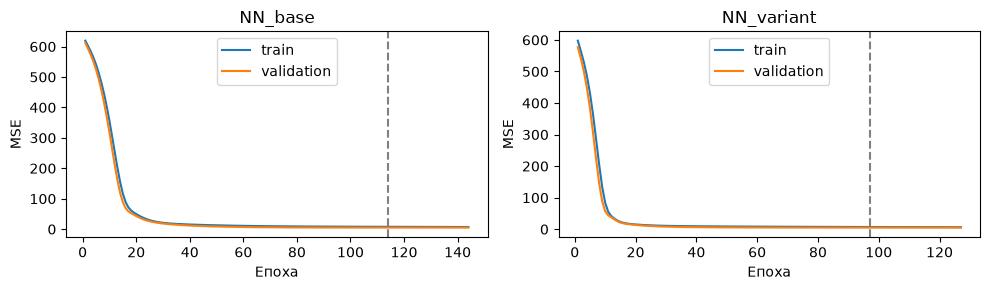

In [20]:
if histories:
    fig, axes = plt.subplots(1, 2, figsize=(10, 3))
    for ax, (name, history) in zip(axes, histories.items()):
        epochs = np.arange(1, len(history['loss']) + 1)
        ax.plot(epochs, history['loss'], label='train')
        ax.plot(epochs, history['val_loss'], label='validation')
        ax.axvline(run_infos[name]['best_epoch'], color='gray', linestyle='--')
        ax.set(title=name, xlabel='Епоха', ylabel='MSE'); ax.legend()
    plt.tight_layout(); plt.show()
else:
    print('Криві навчання з’являться після виконання TensorFlow-блока.')

## Вибір за validation, потім фінальна перевірка

In [21]:
validation_table = pd.DataFrame({
    name: regression_metrics(y_val, predict_values(model, X_val_p))
    for name, model in models.items()
}).T.add_prefix('val_')
best_overall_name = validation_table['val_RMSE'].idxmin()
nn_names = [name for name in models if name.startswith('NN_')]
best_nn_name = validation_table.loc[nn_names, 'val_RMSE'].idxmin() if nn_names else None
print('Обрана модель:', best_overall_name, ' | Обрана NN:', best_nn_name)
display(validation_table.round(3))

# Нижче — фінальне оцінювання, вибір уже зроблено.
test_predictions = {name: predict_values(model, X_test_p) for name, model in models.items()}
test_table = pd.DataFrame({name: regression_metrics(y_test, pred)
                           for name, pred in test_predictions.items()}).T.add_prefix('test_')
results = validation_table.join(test_table)
for name, info in run_infos.items():
    for key, value in info.items(): results.loc[name, key] = value
display(results.round(3))
results.to_csv(ARTIFACTS / 'model_comparison.csv', index_label='model')

Обрана модель: NN_variant  | Обрана NN: NN_variant


,val_MAE,val_RMSE,val_R2
Dummy,5.827,7.012,-0.002
LinearRegression,2.448,3.098,0.804
NN_base,1.763,2.263,0.896
NN_variant,1.753,2.262,0.896


,val_MAE,val_RMSE,val_R2,test_MAE,test_RMSE,test_R2,epochs_run,best_epoch
Dummy,5.827,7.012,-0.002,6.710,8.107,-0.000,NaN,NaN
LinearRegression,2.448,3.098,0.804,2.323,2.964,0.866,NaN,NaN
NN_base,1.763,2.263,0.896,1.998,2.648,0.893,144.0,114.0
NN_variant,1.753,2.262,0.896,1.690,2.386,0.913,127.0,97.0


## Найбільші помилки: від показника до автомобіля

Аналізуємо: NN_variant


,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,actual_mpg,predicted_mpg,residual,absolute_error
334,3,70.0,100.0,2420.0,12.5,80,3,23.700001,32.829906,-9.129906,9.129906
384,4,91.0,67.0,1965.0,15.7,82,3,32.000000,38.628159,-6.628159,6.628159
108,4,97.0,88.0,2279.0,19.0,73,3,20.000000,26.204086,-6.204086,6.204086
196,4,98.0,60.0,2164.0,22.1,76,1,24.500000,28.967262,-4.467262,4.467262
101,6,198.0,95.0,2904.0,16.0,73,1,23.000000,19.163172,3.836828,3.836828


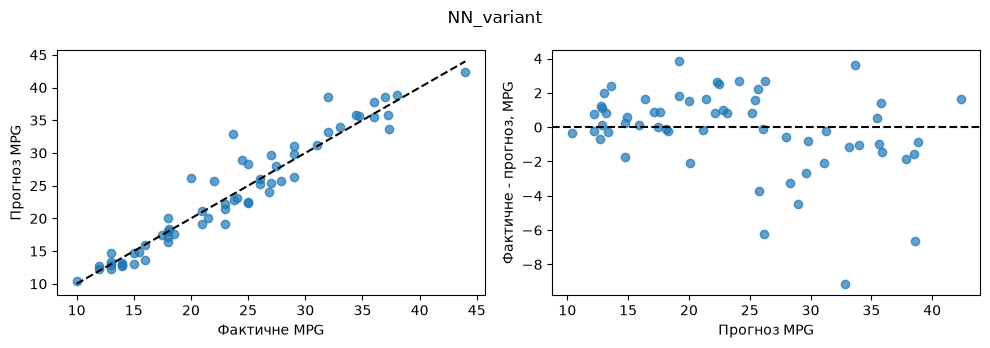

In [22]:
analysis_name = best_nn_name or best_overall_name
print('Аналізуємо:', analysis_name)
predicted = test_predictions[analysis_name]
errors = X_test.copy()
errors['actual_mpg'] = y_test
errors['predicted_mpg'] = predicted
errors['residual'] = y_test.to_numpy() - predicted
errors['absolute_error'] = errors.residual.abs()
display(errors.nlargest(5, 'absolute_error'))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].scatter(y_test, predicted, alpha=0.7)
limits = [min(y_test.min(), predicted.min()), max(y_test.max(), predicted.max())]
axes[0].plot(limits, limits, 'k--')
axes[0].set(xlabel='Фактичне MPG', ylabel='Прогноз MPG')
axes[1].scatter(predicted, errors.residual, alpha=0.7)
axes[1].axhline(0, color='black', linestyle='--')
axes[1].set(xlabel='Прогноз MPG', ylabel='Фактичне - прогноз, MPG')
fig.suptitle(analysis_name); plt.tight_layout(); plt.show()

## Збереження та прогноз нового автомобіля

In [23]:
def prepare_new_rows(rows, fitted_preprocessor, feature_columns):
    missing, extra = set(feature_columns) - set(rows), set(rows) - set(feature_columns)
    if missing or extra:
        raise ValueError(f'Відсутні: {missing}; зайві: {extra}')
    rows = rows.loc[:, feature_columns].copy()
    for column in feature_columns:
        rows[column] = pd.to_numeric(rows[column], errors='raise')
    if np.isin(rows.to_numpy(dtype=float), np.nan).any():
        raise ValueError('Нескінченні значення')
    
    # Виправляємо отримання категорій із урахуванням структури пайплайна
    cat_transformer = fitted_press = fitted_preprocessor.named_transformers_['cat']
    known = cat_transformer.named_steps['encoder'].categories_[0] if hasattr(cat_transformer, 'named_steps') else cat_transformer.categories_[0]
    
    if not rows.origin.dropna().isin(known).all():
        raise ValueError('Невідома train категорія origin')
    return fitted_preprocessor.transform(rows).astype('float32')

new_car = pd.DataFrame([{'cylinders': 4, 'displacement': 120.0, 'horsepower': 90.0,
                         'weight': 2500.0, 'acceleration': 15.5, 'model_year': 88, 'origin': 2}])

saved_name = best_nn_name or best_overall_name
selected_model = models[saved_name]
is_nn = best_nn_name is not None
model_file = 'best_model.keras' if is_nn else 'classical_model.joblib'
if is_nn:
    selected_model.save(ARTIFACTS / model_file)
else:
    joblib.dump(selected_model, ARTIFACTS / model_file)
joblib.dump(preprocessor, ARTIFACTS / 'preprocessor.joblib')

metadata = {'feature_columns': list(X_train.columns), 'target': 'mpg',
            'weight_unit': 'lb', 'displacement_unit': 'cubic_inch', 'model_year_format': 'two_digit',
            'selected_model': saved_name, 'is_neural_network': is_nn, 'model_file': model_file, 'seed': SEED,
            'versions': {'tensorflow': tf.__version__ if TF_AVAILABLE else None,
                         'scikit_learn': sklearn.__version__, 'joblib': joblib.__version__,
                         'pandas': pd.__version__}}
(ARTIFACTS / 'metadata.json').write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding='utf-8')

# Окремий блок відновлення
restored_metadata = json.loads((ARTIFACTS / 'metadata.json').read_text(encoding='utf-8'))
restored_preprocessor = joblib.load(ARTIFACTS / 'preprocessor.joblib')
restored_path = ARTIFACTS / restored_metadata['model_file']
restored_model = (keras.models.load_model(restored_path) if restored_metadata['is_neural_network']
                  else joblib.load(restored_path))

new_p = prepare_new_rows(new_car, restored_preprocessor, restored_metadata['feature_columns'])
print('Модель:', restored_metadata['selected_model'])
print(f'Новий автомобіль: {predict_values(restored_model, new_p)[0]:.2f} MPG')

probe = X_test.iloc[:3]
before = predict_values(selected_model, preprocessor.transform(probe).astype('float32'))
after = predict_values(restored_model, prepare_new_rows(probe, restored_preprocessor,
                                                        restored_metadata['feature_columns']))
np.testing.assert_allclose(before, after, rtol=1e-5, atol=1e-5)
print('Прогнози до та після збереження збігаються.')

Модель: NN_variant
Новий автомобіль: 43.18 MPG
Прогнози до та після збереження збігаються.


## Дві типові помилки входу

In [24]:
for label, bad in [('Немає weight', new_car.drop(columns='weight')),
                   ('Невідома категорія', new_car.assign(origin=99))]:
    try:
        prepare_new_rows(bad, restored_preprocessor, restored_metadata['feature_columns'])
    except ValueError as error:
        print(label, '-', error)
print('NaN в horsepower допустимий:', prepare_new_rows(
    new_car.assign(horsepower=np.nan), restored_preprocessor,
    restored_metadata['feature_columns']).shape)

Немає weight - Відсутні: {'weight'}; зайві: set()
Невідома категорія - Невідома train категорія origin
NaN в horsepower допустимий: (1, 9)


**Висновок:** Під час виконання лабораторної роботи було успішно побудовано повний пайплайн машинного навчання для регресійного аналізу датасета Auto MPG. Проведено якісну передобробку даних із захистом від витоку, навчено базові класичні моделі та нейронні мережі (зокрема індивідуальну варіативну модель із 64 нейронами). Завдяки механізмам EarlyStopping і ModelCheckpoint контролювалося навчання на валідаційній вибірці, а найкращі результати та препроцесор було успішно збережено й перевірено на нових даних.